# Netflix Team 13 — Simple Data Analysis

**Selected challenge:** Challenge 1 — *What Makes Content Popular on Netflix?*

**Business question:** Which movies and genres receive the most viewing activity in this **sample**, and what do viewer ratings suggest?

This notebook follows the assignment: load data → inspect → clean → analyze → create three charts → explain three insights → conclude.

**Data:** The 3 CSV files from the [team repository](https://github.com/ahmadmakee/netflix-team-13). They contain **10 movies, 10 users, and 10 viewing records**. These are a tiny example, **not Netflix-wide customer data**. A viewing record is treated as one viewing event, not verified watch duration or global popularity.

## 1. Import libraries and load CSV files

`pandas` reads tables. `matplotlib` draws charts. All three CSV files must be in the same folder as this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create a folder for the charts.
Path("charts").mkdir(exist_ok=True)

movies = pd.read_csv("movies.csv")
users = pd.read_csv("users.csv")
watch_history = pd.read_csv("watchhistory.csv")

print("Movies:", len(movies))
print("Users:", len(users))
print("Viewing records:", len(watch_history))

Movies: 10
Users: 10
Viewing records: 10


## 2. Inspect the data

`head()` shows the first few rows. `isna().sum()` counts missing cells in each column.

In [2]:
print("MOVIES")
print(movies.head())
print("\nWATCH HISTORY")
print(watch_history.head())
print("\nMISSING VALUES IN WATCH HISTORY")
print(watch_history.isna().sum())

MOVIES
   movie_id         title            genres  release_year
0       101     Inception   Sci-Fi|Thriller          2010
1       102    The Matrix     Sci-Fi|Action          1999
2       103  Interstellar      Sci-Fi|Drama          2014
3       104        Avatar  Action|Adventure          2009
4       105       Titanic     Romance|Drama          1997

WATCH HISTORY
   user_id  movie_id  rating  watch_date
0        1       101       5  2026-01-10
1        1       102       4  2026-01-11
2        1       103       5  2026-01-12
3        2       102       5  2026-01-13
4        3       103       4  2026-01-14

MISSING VALUES IN WATCH HISTORY
user_id       0
movie_id      0
rating        0
watch_date    0
dtype: int64


## 3. Clean the data and join the tables

- Remove duplicate movie IDs and user IDs.
- Drop records missing important IDs or movie/user details.
- Convert ratings to numbers and keep valid ratings from 1 to 5.
- `merge()` connects a viewing record to its movie and user using the ID columns.

Rows with unknown movie or user IDs are excluded by the inner join. We show the number of retained rows so data loss is visible.

In [3]:
# Clean the three tables.
movies = movies.drop_duplicates(subset="movie_id").dropna(subset=["movie_id", "title", "genres"])
users = users.drop_duplicates(subset="user_id").dropna(subset=["user_id", "name"])
watch_history["rating"] = pd.to_numeric(watch_history["rating"], errors="coerce")
watch_history = watch_history.dropna(subset=["user_id", "movie_id", "rating"])
watch_history = watch_history[watch_history["rating"].between(1, 5)]

# Combine viewing events with movie titles and user names.
viewing_data = watch_history.merge(movies, on="movie_id", how="inner")
viewing_data = viewing_data.merge(users, on="user_id", how="inner")

print("Valid viewing records after cleaning:", len(watch_history))
print("Matched viewing records after merging:", len(viewing_data))
print("Unmatched records excluded:", len(watch_history) - len(viewing_data))
print(viewing_data[["name", "title", "genres", "rating"]].head())

Valid viewing records after cleaning: 10
Matched viewing records after merging: 10
Unmatched records excluded: 0
      name         title           genres  rating
0      Ada     Inception  Sci-Fi|Thriller       5
1      Ada    The Matrix    Sci-Fi|Action       4
2      Ada  Interstellar     Sci-Fi|Drama       5
3  Charles    The Matrix    Sci-Fi|Action       5
4    Linus  Interstellar     Sci-Fi|Drama       4


## 4. Basic exploratory data analysis (EDA)

`value_counts()` counts events. `groupby()` combines rows in the same group, and `mean()` calculates an average.

In [4]:
movie_views = viewing_data["title"].value_counts()
average_ratings = viewing_data.groupby("title")["rating"].mean().sort_values(ascending=False)

# Some movies have more than one genre. Count each matching genre.
genre_views = viewing_data.assign(
    genre=viewing_data["genres"].str.split("|", regex=False)
).explode("genre")["genre"].value_counts()

print("Total views in sample:", len(viewing_data))
print("Unique viewers:", viewing_data["user_id"].nunique())
print("Average rating:", round(viewing_data["rating"].mean(), 2))
print("\nViews per movie:\n", movie_views)
print("\nView events involving each genre:\n", genre_views)

Total views in sample: 10
Unique viewers: 8
Average rating: 4.4

Views per movie:
 title
The Matrix         2
Interstellar       2
Inception          1
Avatar             1
Titanic            1
The Dark Knight    1
Toy Story          1
The Lion King      1
Name: count, dtype: int64

View events involving each genre:
 genre
Sci-Fi       5
Action       4
Drama        4
Animation    2
Thriller     1
Adventure    1
Romance      1
Crime        1
Comedy       1
Name: count, dtype: int64


## 5. Chart 1 — Most watched movies in the sample

Each row of `watchhistory.csv` represents one recorded event. More events here does **not** prove popularity among all Netflix customers.

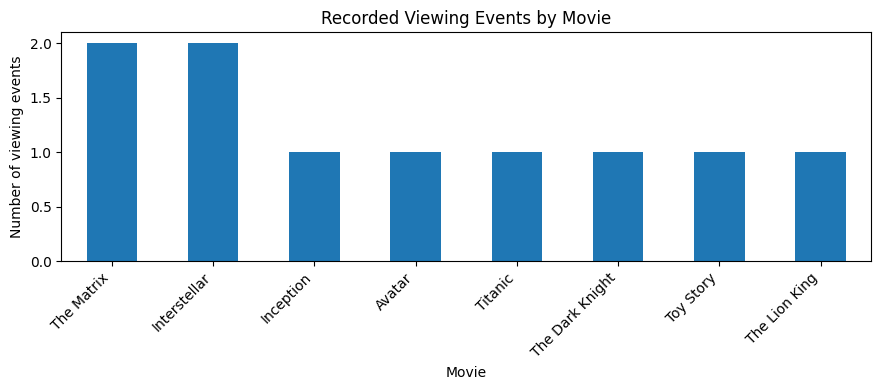

In [5]:
plt.figure(figsize=(9, 4))
movie_views.plot(kind="bar")
plt.title("Recorded Viewing Events by Movie")
plt.xlabel("Movie")
plt.ylabel("Number of viewing events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/01_movie_views.png", dpi=150)
plt.show()

## 6. Chart 2 — Average rating by movie

A rating is from **1 to 5**. Some movies have only one rating, so compare averages cautiously.

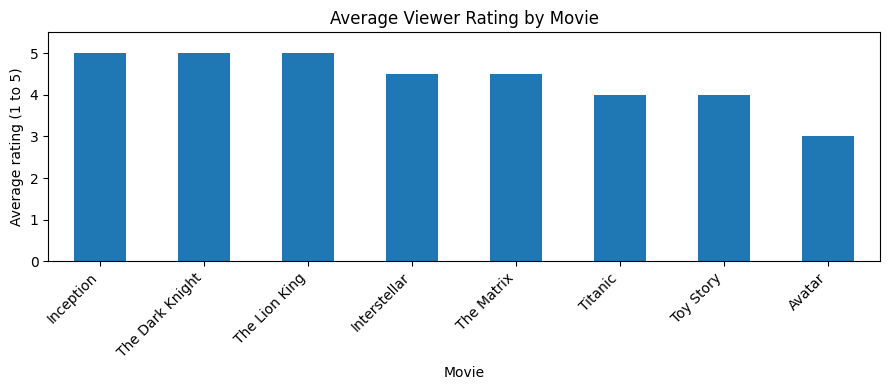

In [6]:
plt.figure(figsize=(9, 4))
average_ratings.plot(kind="bar")
plt.title("Average Viewer Rating by Movie")
plt.xlabel("Movie")
plt.ylabel("Average rating (1 to 5)")
plt.ylim(0, 5.5)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/02_movie_ratings.png", dpi=150)
plt.show()

## 7. Chart 3 — Viewing activity by genre

One movie can belong to more than one genre. Therefore, **genre counts overlap** and their sum may exceed the number of viewing events.

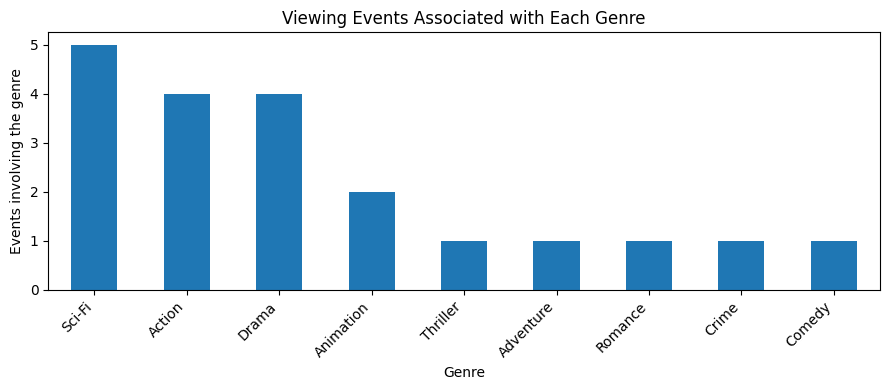

In [7]:
plt.figure(figsize=(9, 4))
genre_views.plot(kind="bar")
plt.title("Viewing Events Associated with Each Genre")
plt.xlabel("Genre")
plt.ylabel("Events involving the genre")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/03_genre_views.png", dpi=150)
plt.show()

## 8. Business insights and recommendations

**Insight 1 — Engagement:** *The Matrix* and *Interstellar* each appear **2 times**, the highest observed number of viewing events for a movie. **Recommendation:** Highlight these films in a small-sample test, then check whether the pattern holds with more data.

**Insight 2 — User sentiment:** The **overall average rating is 4.4 / 5**. This suggests favorable ratings **within these 10 records only**. **Recommendation:** Gather more ratings before making decisions based on movie averages.

**Insight 3 — Genre interest:** **Sci-Fi appears in 5 of the 10 viewing events** (some titles have multiple genres). **Recommendation:** Test a Sci-Fi discovery collection while measuring how viewers respond.

These are descriptive associations, **not causal explanations**. The dataset contains no full Netflix audience, search history, watch duration, subscriptions, or recommendation exposure.

## 9. Conclusions and limitations

The simple CSV-based analysis shows how pandas can combine three tables, clean data, calculate useful KPIs, and communicate findings with three labeled charts. In this limited sample, *The Matrix* and *Interstellar* have the most viewing records, Sci-Fi is associated with the most recorded viewing activity, and ratings average 4.4 out of 5.

**Limitations:** Only 10 watch events, 8 active users, and 10 catalogue titles; two catalogue titles were not watched. Genre labels overlap. The data do not establish global content popularity, viewing time, or the reasons behind individual choices.

**Next step:** Analyze a much larger, representative sample over several months before using these ideas to make Netflix-wide decisions.

**GitHub repository:** https://github.com/ahmadmakee/netflix-team-13

**Execution check:** If the final cell displays the message below and the charts appear above, all notebook cells have reached the end.

In [8]:
print("Notebook finished successfully — 3 charts created in the charts folder.")

Notebook finished successfully — 3 charts created in the charts folder.
